# Hyperparameter Analysis for MIPROv2 Optimizer: Nanozyme Data Extraction

This notebook calculates the optimal hyperparameters for the **MIPROv2 (DSPy)** prompt optimization pipeline: the Search Space Capacity ($K$) and the Optimization Budget ($T$).

Unlike continuous AutoML environments, optimizing prompt configurations operates in a **discrete categorical space**. A mathematically rigorous approach to defining this space prevents semantic redundancy and avoids the diminishing returns of excessive LLM API calls.

## 1. Theoretical Framework: Pragmatic Similarity & The Coupon Collector Model

Standard Semantic Textual Similarity (STS) is often insufficient for prompt optimization because it fails to capture **pragmatic and functional intent** (e.g., the difference between asking for a direct answer vs. a step-by-step reasoning process). 

To find the optimal number of instruction candidates ($N_{instr}$), we must account for the **Teacher LLM's generative diversity** and identify the point of **semantic saturation**. We model this using a two-phase approach:

**Phase A (Heuristic Validation):** 
We map generated instructions into a dense vector space using an advanced embedding model. We then apply **Agglomerative Hierarchical Clustering (AHC)** using cosine distance and average linkage. To identify the number of latent functional modes ($C$), we truncate the hierarchy at a fixed cosine distance threshold.

**Phase B (Simulation-Based Stopping Criterion):** 
Black-box optimizers blindly request $N$ instructions. To prevent token waste, we model this as the **Coupon Collector's Problem**. We simulate sampling $N$ instructions (with replacement). Let $\mathbb{E}[U(N)]$ be the expected number of unique conceptual modes discovered. The marginal utility is $MU(N) = \mathbb{E}[U(N)] - \mathbb{E}[U(N-1)]$. We set $N_{instr}$ at the exact point where the probability of discovering a novel functional mode drops below $10\%$.

## 2. Setup & Configuration

In [1]:
!pip install -q -U transformers accelerate sentence-transformers
!pip install -q scikit-learn matplotlib numpy scipy

import os, json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown

from sklearn.cluster import AgglomerativeClustering
from sentence_transformers import SentenceTransformer
from umap import UMAP
import torch

import warnings
warnings.filterwarnings("ignore")

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# --- Configuration ---
KAGGLE_WORKING_DIR = Path("/kaggle/working")
INSTRUCTIONS_PATH = "/kaggle/input/datasets/arutamonofu/instructions-pool/instructions_pool.json"

N_DEMO = 12 

# Hyperparameters for the Generative Diversity Simulation
MIN_MARGINAL_UTILITY = 0.10
MC_SIMULATIONS = 500

# TPE Optimization Constraints
TPE_COVERAGE_RATIO = 0.30
T_MAX_CAP = 60

print(f"Configured with N_demo = {N_DEMO}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 60.3 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.4/512.4 kB 30.1 MB/s eta 0:00:00


2026-03-20 19:52:45.855919: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774036365.879586    1141 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774036365.886609    1141 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774036365.906445    1141 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774036365.906466    1141 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774036365.906469    1141 computation_placer.cc:177] computation placer alr

Configured with N_demo = 12


## 3. Phase A & B: Latent Mode Discovery and Generative Simulation

In [2]:
torch.cuda.empty_cache()

# 1. Load Data
with open(INSTRUCTIONS_PATH, 'r', encoding='utf-8') as f:
    data = json.load(f)
    instructions = data.get("instructions", data) if isinstance(data, dict) else data
print(f"Loaded {len(instructions)} instruction candidates.")

Loaded 47 instruction candidates.


In [3]:
# 2. Generate Embeddings
model_id = 'codefuse-ai/F2LLM-4B'
print(f"Loading SentenceTransformer: {model_id}...")

embedder = SentenceTransformer(
    model_id, 
    device='cuda',
    trust_remote_code=True,
    model_kwargs={'torch_dtype': torch.float16, 'low_cpu_mem_usage': True}
)

task_description = "Represent this LLM prompt for clustering by prioritizing its prompt engineering strategy over its domain content. Assign the highest analytical weight to: 1) The specified persona and tone; 2) The structure of the output schema (e.g., JSON topology, Markdown tables); 3) The formulation of conditional logic and rules. Assign a significantly lower weight to the scientific vocabulary (nanozymes, chemistry, H2O2, etc.), as it is contextually similar across all prompts. Similarity should primarily reflect shared prompt engineering techniques."

formatted_prompts =[f"Instruct: {task_description}\nQuery: {p}" for p in instructions]

batch_size = 8  
all_embeddings =[]
for i in range(0, len(formatted_prompts), batch_size):
    batch = formatted_prompts[i:i + batch_size]
    batch_embeddings = embedder.encode(batch, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    all_embeddings.append(batch_embeddings)
    torch.cuda.empty_cache()
    
embeddings = np.vstack(all_embeddings)
print(f"Generated embeddings shape: {embeddings.shape}")

Loading SentenceTransformer: codefuse-ai/F2LLM-4B...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Generated embeddings shape: (47, 2560)


In [4]:
# 3. PHASE A: Hierarchical Clustering (Distance Threshold Validation)
DISTANCE_THRESHOLD = 0.05

final_clusterer = AgglomerativeClustering(
    n_clusters=None, 
    distance_threshold=DISTANCE_THRESHOLD, 
    metric='cosine', 
    linkage='average'
)
cluster_labels = final_clusterer.fit_predict(embeddings)
optimal_c = final_clusterer.n_clusters_

print(f"Phase A: Discovered {optimal_c} latent functional modes.")

Phase A: Discovered 8 latent functional modes.


In [5]:
# 4. PHASE B: Simulation-Based Stopping Criterion (Coupon Collector)
n_total = len(instructions)
n_requests = np.arange(1, n_total + 1)
expected_unique_clusters =[]

for n in n_requests:
    draws = np.random.choice(cluster_labels, size=(MC_SIMULATIONS, n), replace=True)
    unique_counts = np.array([len(np.unique(row)) for row in draws])
    expected_unique_clusters.append(np.mean(unique_counts))

expected_unique = np.array(expected_unique_clusters)

marginal_utility = np.insert(np.diff(expected_unique), 0, expected_unique[0])
saturation_points = np.where(marginal_utility < MIN_MARGINAL_UTILITY)[0]

optimal_n_instr = (saturation_points[0] + 1) if len(saturation_points) > 0 else n_total
print(f"Phase B: Generative saturation reached at N_instr = {optimal_n_instr}")

Phase B: Generative saturation reached at N_instr = 11


## 4. Visualizing Generative Diversity & Saturation

The dual-axis plot below illustrates the expected discovery of unique instruction modes against the diminishing marginal utility (the probability of novel generation), alongside the hierarchical structure of the prompt space.

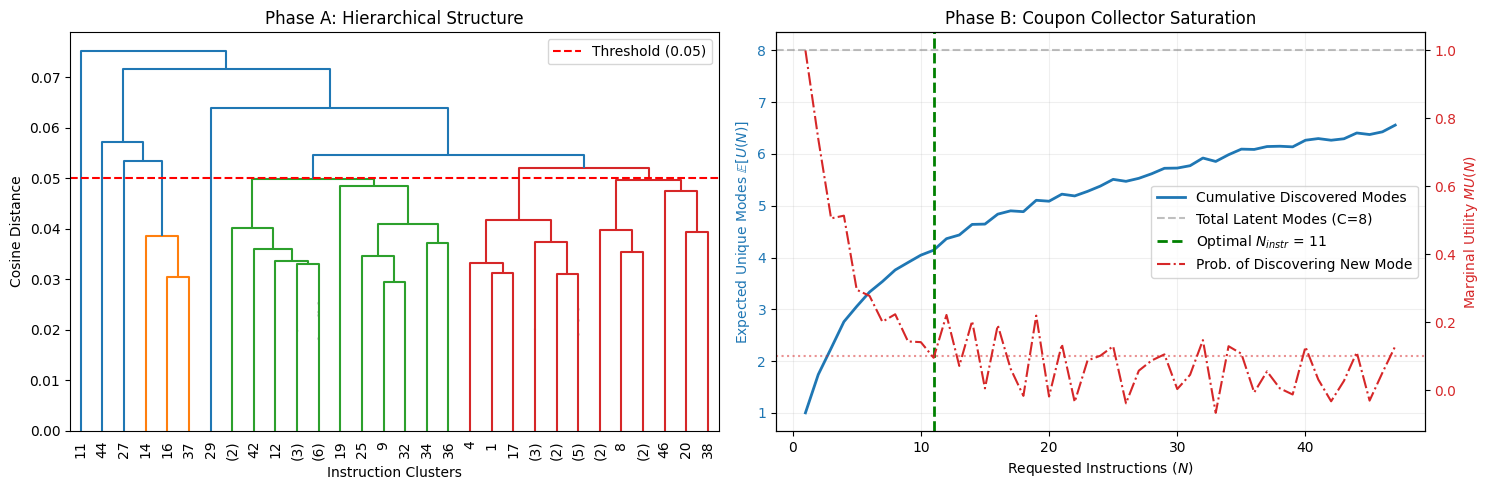

In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(embeddings, method='average', metric='cosine')

fig, (ax_dendro, ax_sim) = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Phase A (Dendrogram) ---
dendro = dendrogram(
    Z, 
    ax=ax_dendro, 
    truncate_mode='lastp',
    p=30, 
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
ax_dendro.axhline(y=DISTANCE_THRESHOLD, color='r', linestyle='--', label=f'Threshold ({DISTANCE_THRESHOLD})')
ax_dendro.set_title('Phase A: Hierarchical Structure')
ax_dendro.set_xlabel('Instruction Clusters')
ax_dendro.set_ylabel('Cosine Distance')
ax_dendro.legend()

# --- Plot 2: Phase B (Coupon Collector) ---
color1 = '#1f77b4'
ax_sim.set_xlabel('Requested Instructions ($N$)')
ax_sim.set_ylabel('Expected Unique Modes $\mathbb{E}[U(N)]$', color=color1)
ax_sim.plot(n_requests, expected_unique, '-', color=color1, linewidth=2, label='Cumulative Discovered Modes')
ax_sim.axhline(optimal_c, color='gray', linestyle='--', alpha=0.5, label=f'Total Latent Modes (C={optimal_c})')
ax_sim.tick_params(axis='y', labelcolor=color1)

ax_mu = ax_sim.twinx()  
color2 = '#d62728'
ax_mu.set_ylabel('Marginal Utility $MU(N)$', color=color2)
ax_mu.plot(n_requests, marginal_utility, '-.', color=color2, label='Prob. of Discovering New Mode')
ax_mu.axhline(MIN_MARGINAL_UTILITY, color=color2, linestyle=':', alpha=0.5)
ax_mu.tick_params(axis='y', labelcolor=color2)

ax_sim.axvline(optimal_n_instr, color='green', linestyle='--', linewidth=2, label=f'Optimal $N_{{instr}}$ = {optimal_n_instr}')
ax_sim.set_title('Phase B: Coupon Collector Saturation')

lines_1, labels_1 = ax_sim.get_legend_handles_labels()
lines_2, labels_2 = ax_mu.get_legend_handles_labels()
ax_sim.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')
ax_sim.grid(alpha=0.2)

fig.tight_layout() 
plt.show()

Computing UMAP projection...
✓ Shape: (47, 2)


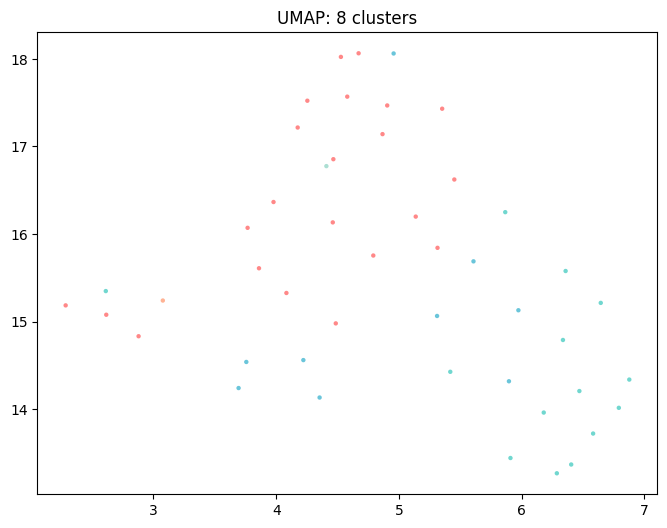

In [28]:
torch.cuda.empty_cache()

print("Computing UMAP projection...")
umap_model = UMAP(n_components=2, n_neighbors=10, min_dist=0.1, 
                  metric='cosine', random_state=42)
umap_embeddings = umap_model.fit_transform(embeddings)
print(f"✓ Shape: {umap_embeddings.shape}")

plt.figure(figsize=(8, 6))
cluster_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
for cluster_id in range(optimal_c):
    mask = cluster_labels == cluster_id
    plt.scatter(umap_embeddings[mask, 0], umap_embeddings[mask, 1],
                c=cluster_colors[cluster_id % len(cluster_colors)],
                s=10, alpha=0.8, edgecolors='none', label=f'{cluster_id}')
plt.title(f'UMAP: {optimal_c} clusters', fontsize=12)
plt.show()

## 5. Calculating Search Space ($K$) and TPE Budget ($T$)

With $N_{demo}$ and $N_{instr}$ scientifically established, we construct the final hyperparameter configuration.

**Bayesian Optimization Budget Allocation:**
The total budget $T$ is decomposed into $T = T_{init} + T_{BO}$. Empirical heuristics for categorical domains show that evaluating $\approx 30\%$ of $K$ provides a high probability of finding a top-tier configuration, while capping at $T_{max} = 60$ protects against diminishing marginal returns.

In [11]:
K_space = int(optimal_n_instr * N_DEMO)
T_calculated = int(np.round(K_space * TPE_COVERAGE_RATIO))
T_optimal = min(T_calculated, T_MAX_CAP)

display(Markdown("### Final MIPROv2 Hyperparameter Configuration"))
display(Markdown(f"- **Latent Modes Discovered ($C$):** `{optimal_c}`"))
display(Markdown(f"- **Instructions ($N_{{instr}}$):** `{optimal_n_instr}` (Simulation-Based Stopping Criterion)"))
display(Markdown(f"- **Demonstrations ($N_{{demo}}$):** `{N_DEMO}` (Hard-Example Mining)"))
display(Markdown(f"- **Search Space ($K$):** `{K_space}` discrete combinations"))
display(Markdown(f"- **Optimization Budget ($T$):** `{T_optimal}` trials ($\\approx {T_optimal/K_space*100:.1f}\\%$ coverage)"))

config = {
    "latent_modes": int(optimal_c),
    "n_instr": int(optimal_n_instr),
    "n_demo": N_DEMO,
    "search_space_K": K_space,
    "optimization_budget_T": T_optimal,
    "coverage_ratio": T_optimal / K_space,
    "generated_at": datetime.now().isoformat()
}

### Final MIPROv2 Hyperparameter Configuration

- **Latent Modes Discovered ($C$):** `8`

- **Instructions ($N_{instr}$):** `11` (Simulation-Based Stopping Criterion)

- **Demonstrations ($N_{demo}$):** `12` (Hard-Example Mining)

- **Search Space ($K$):** `132` discrete combinations

- **Optimization Budget ($T$):** `40` trials ($\approx 30.3\%$ coverage)